![alt text](../../pythonexposed-high-resolution-logo-black.jpg "Optionele titel")

### Matplotlib - oplossingen

#### BEL20 aandeel

1. Download de koersgegevens inzake een aandeel naar keus uit de Bel20 van Yahoo Finance voor het afgelopen jaar.  Je kan hiervoor de library yfinance gebruiken.  
- Plot de data
- Bepaal de dagelijkse procentuele wijziging van de koers en plot deze
- Markeer enkele uitschieters door tekst en via een pijl
- Plaats een annotatie op je figuur
- Zoom in op de laatste 3 maanden

In [101]:
import matplotlib.image as mpimg
import numpy as np
import pandas as pd

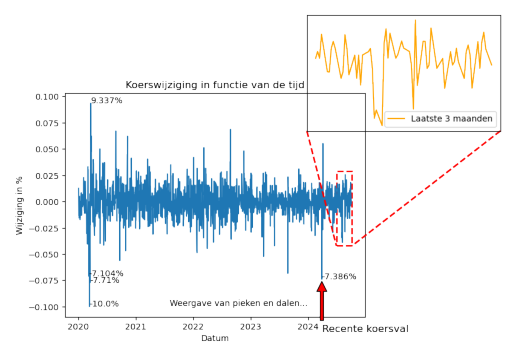

In [102]:
img = mpimg.imread('../../IMAGES/BEL20.png')
plt.imshow(img)
plt.axis('off')  # Verberg de assen
plt.show()

In [1]:
!pip install yfinance

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.0/3.0 MB 7.5 MB/s eta 0:00:0000:0100:01
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 94.6/94.6 kB 2.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 112.2/112.2 kB 4.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 12.7 MB/s eta 0:00:0000:0100:01
  Created wheel for peewee: filename=peewee-3.17.6-cp311-cp311-linux_x86_64.whl size=274820 sha256=a6e8d71d5ab8b914f0f167d1144fd73495e944ebdfd590949fae6aa6a60b78ed
  Stored in directory: /home/jovyan/.cache/pip/wheels/1c/09/7e/9f659fde248ecdc1722a142c1d744271aad3914a0afc191058
Successfully built peewee


In [26]:
import yfinance as yf
import numpy as np
import matplotlib.pyplot as plt

# Stap 1: Download de gegevens voor TESB.BR en SYENS.BR
start_date = '2020-01-01'
end_date = '2024-10-01'

aandeel_1 = 'TESB.BR'

koers = yf.download(aandeel_1, start=start_date, end=end_date)
# Procentuele verandering
koers['change'] = koers['Close'].pct_change()

koers.head()

[*********************100%***********************]  1 of 1 completed


,Open,High,Low,Close,Adj Close,Volume,change
Date,,,,,,,
2020-01-02,31.400000,32.099998,31.400000,31.799999,30.078087,10994,NaN
2020-01-03,31.799999,32.200001,31.600000,32.200001,30.456429,13812,0.012579
2020-01-06,31.850000,31.900000,31.450001,31.700001,29.983503,11109,-0.015528
2020-01-07,31.799999,32.500000,31.799999,31.799999,30.078087,29342,0.003155
2020-01-08,31.799999,31.950001,31.650000,31.850000,30.125381,10004,0.001572


In [27]:
koers.describe()

,Open,High,Low,Close,Adj Close,Volume,change
count,1219.000000,1219.000000,1219.000000,1219.000000,1219.000000,1219.000000,1218.000000
mean,30.405906,30.675144,30.089631,30.365751,28.954234,25841.639869,-0.000064
std,3.861601,3.884254,3.814087,3.861739,3.417429,34971.320304,0.015214
min,20.350000,20.950001,19.639999,20.049999,18.964329,1379.000000,-0.100000
25%,27.175000,27.475000,26.799999,27.075000,26.005533,12759.500000,-0.007752
50%,30.600000,30.799999,30.250000,30.549999,29.207708,18522.000000,0.000000
75%,33.099998,33.400002,32.700001,33.099998,31.307695,28169.500000,0.008159
max,40.000000,40.000000,39.650002,39.950001,37.786781,662172.000000,0.093366


In [46]:
# Wat is de grootste koersval op een dag?
print(f"De grootste daling deed zich voor op record nummer {koers['change'].argmin()} op datum {koers.index[koers['change'].argmin()]}")
print(f"De daling op die dag was {round(koers.iloc[koers['change'].argmin()]['change']*100,10)}%")

# Wat is de grootste koersstijging op een dag?
print(f"De grootste stijging deed zich voor op record nummer {koers['change'].argmax()} op datum {koers.index[koers['change'].argmax()]}")
print(f"De stijging op die dag was {round(koers.iloc[koers['change'].argmax()]['change']*100,10)}%")

De grootste daling deed zich voor op record nummer 50 op datum 2020-03-12 00:00:00
De daling op die dag was -10.000003114%
De grootste stijging deed zich voor op record nummer 56 op datum 2020-03-20 00:00:00
De stijging op die dag was 9.336607287%


In [71]:
# Zoek enkele uitschieters
uitschieters = koers[abs(koers['change'])>0.07]
uitschieters.head(20)

,Open,High,Low,Close,Adj Close,Volume,change
Date,,,,,,,
2020-03-09,26.400000,27.000000,25.500000,25.500000,24.119221,47091,-0.071038
2020-03-12,23.000000,23.549999,21.500000,22.049999,20.856031,106438,-0.100000
2020-03-16,21.450001,21.450001,19.639999,20.350000,19.248085,66177,-0.077097
2020-03-20,21.700001,22.950001,21.700001,22.250000,21.045202,49132,0.093366
2024-03-27,24.500000,24.700001,23.250000,24.450001,23.725199,136338,-0.073864


In [88]:
from datetime import timedelta
# neem de koers van de laatste 3 maanden
# Bereken de huidige datum en de datum van 3 maanden geleden
huidige_datum = koers.index.max()
drie_maanden_geleden = huidige_datum - timedelta(days=90)

# Filter de laatste 3 maanden data met loc
laatste_3_maanden = koers.loc[drie_maanden_geleden:huidige_datum]

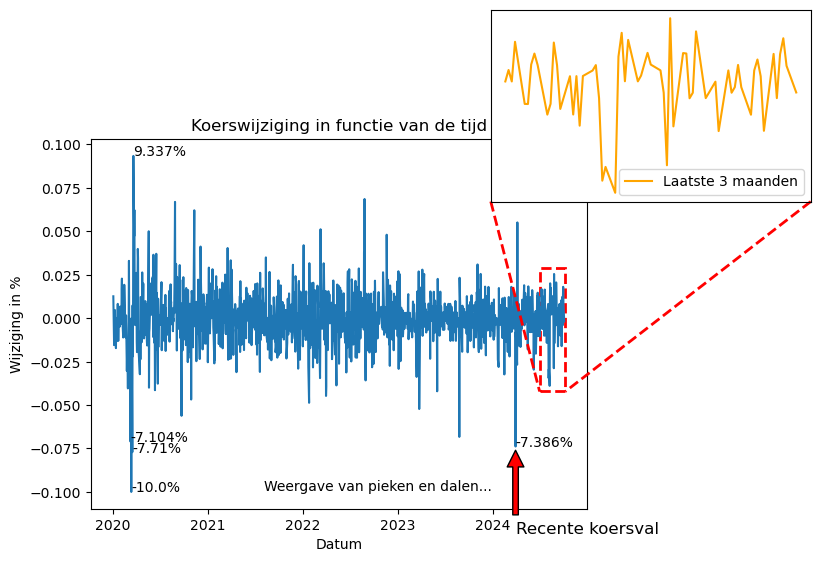

In [98]:
from mpl_toolkits.axes_grid1.inset_locator import inset_axes, mark_inset


fig, ax = plt.subplots()
ax.plot(koers.index, koers['change'].values)
ax.set_xlabel("Datum")
ax.set_ylabel("Wijziging in %")
ax.set_title("Koerswijziging in functie van de tijd")

# Itereer over de uitschieters om een ax.text toe te voegen
for index, row in uitschieters.iterrows():
    ax.text(index, row['change'], f"{round(row['change']*100,3)}%", fontsize=10, ha='left')

# Arrow
ax.annotate(
    'Recente koersval', 
    xy=(uitschieters.index[4], uitschieters.iloc[4]['change']), 
    xytext=(uitschieters.index[4], uitschieters.iloc[4]['change'] - 0.05),
    arrowprops=dict(facecolor='red', shrink=0.05),
    fontsize=12
)

# Extra uitleg
ax.text(0.35,0.05,"Weergave van pieken en dalen...", transform=ax.transAxes)

# Inset
# Dit voegt een nieuwe as toe aan de figuur, die op (50%, 50%) van de figuur wordt geplaatst en 
# een breedte en hoogte heeft van 40% van de volledige figuur.
# Met bijvoorbeeld een negatieve waarde voor 'left' kun je de inset deels buiten de figuur laten vallen
# ax_inset = fig.add_axes([0.5, 0.5, 0.4, 0.4])
ax_inset = fig.add_axes([0.75, 0.75, 0.5, 0.4])  # De 'left' waarde is groter dan 0.5, waardoor de inset uit de plot komt

ax_inset.plot(laatste_3_maanden.index, laatste_3_maanden['change'], label='Laatste 3 maanden', color='orange')

ax_inset.set_xticks([])  # Verwijder X-ticks indien gewenst
ax_inset.set_yticks([])  # Verwijder Y-ticks indien gewenst

# Voeg de legende toe aan de inset plot
ax_inset.legend(loc='best')  # Dit zorgt ervoor dat de legende wordt weergegeven in de inset

# Markeer de inset
# Teken het rode kader en verbindingslijnen
mark_inset(ax, ax_inset, loc1=3, loc2=4, fc="none", ec="red", lw=2, ls="--")

# Afbeelding opslaan met bbox_inches='tight' om alles in beeld te houden
plt.savefig("../../IMAGES/BEL20.png", bbox_inches='tight', transparent=True)

plt.show()

2. Lees de dataset 'adult' in.  Maak een 2D Histogram van opleidingsniveau en uren per week, en een 3D histogram van opleidingsniveau, werkuren en inkomen.

In [109]:
# Dataset: adult.csv (inkomen van volwassenen)

incomes = pd.read_csv('../06 - Exercises/adult.csv')

incomes.head()

,age,workclass,fnlwgt,education,educational-num,marital-status,occupation,relationship,race,gender,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,226802,11th,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,89814,HS-grad,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,336951,Assoc-acdm,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,160323,Some-college,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,?,103497,Some-college,10,Never-married,?,Own-child,White,Female,0,0,30,United-States,<=50K


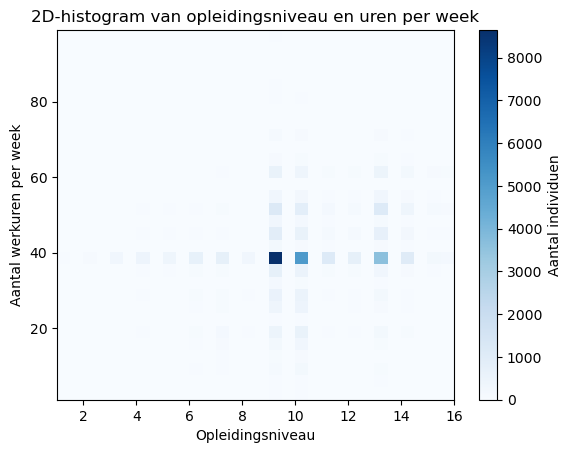

In [110]:
# Maak een 2D-histogram
plt.hist2d(incomes['educational-num'], incomes['hours-per-week'], bins=[30, 30], cmap='Blues')

# # Voeg een kleurstaaf toe om de waarden van de bins te tonen
plt.colorbar(label='Aantal individuen')

# Labels en titel
plt.xlabel('Opleidingsniveau')
plt.ylabel('Aantal werkuren per week')
plt.title('2D-histogram van opleidingsniveau en uren per week')

plt.savefig("../../IMAGES/2DHIST.png", bbox_inches='tight', transparent=True)

# # Toon de grafiek
plt.show()

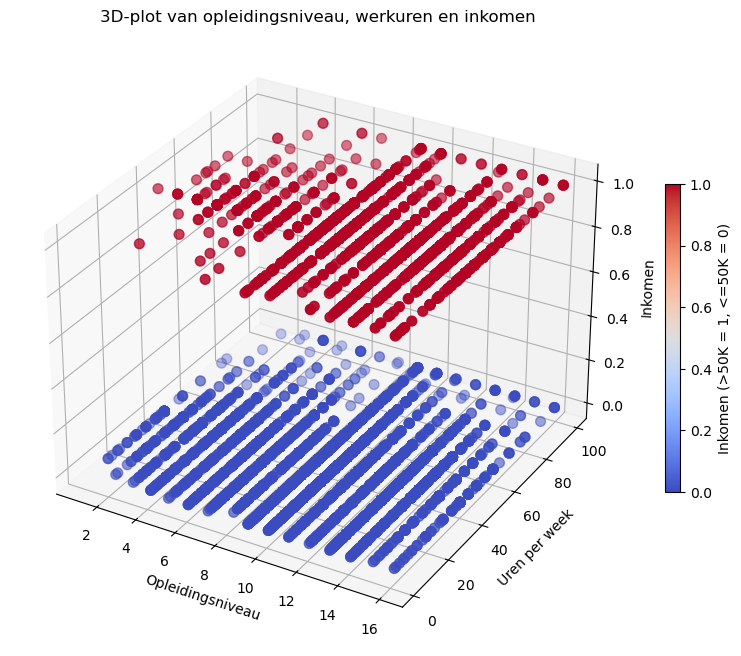

In [111]:
# Maak een 3D-histogram
from mpl_toolkits.mplot3d import Axes3D

# Voorwaarden instellen
education = incomes['educational-num']
hours_per_week = incomes['hours-per-week']
income = incomes['income'].apply(lambda x: 1 if x == '>50K' else 0)  # Inkomenscategorie

# Maak een 3D figuur
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection='3d')

# 3D scatter plot maken
sc = ax.scatter(education, hours_per_week, income, c=income, cmap='coolwarm', s=50)

# Voeg kleurstaaf toe voor de inkomenscategorieën
cbar = plt.colorbar(sc, ax=ax, shrink=0.5)
cbar.set_label('Inkomen (>50K = 1, <=50K = 0)')

# Labels en titel
ax.set_xlabel('Opleidingsniveau')
ax.set_ylabel('Uren per week')
ax.set_zlabel('Inkomen')
ax.set_title('3D-plot van opleidingsniveau, werkuren en inkomen')

plt.savefig("../../IMAGES/3DHIST.png", bbox_inches='tight', transparent=True)

# Toon de grafiek
plt.show()